# Sujet 3 · Optimisation : gradient simple vs recuit simulé

**But.** Minimiser $h(x) = x^2 + 3x\cos x$ sur $[-8\pi, 8\pi]$ en partant de $x_0 = 7{,}5$, point
situé dans le bassin d'un minimum **local** non global, avec un algorithme déterministe (gradient)
puis un algorithme stochastique (recuit simulé), et comparer.

Énoncé : [enonce.md](enonce.md) · démonstrations complètes : [demonstrations.md](demonstrations.md) ·
Matlab → Python : [matlab_python.md](matlab_python.md) · code : `src/stats_td/optimisation.py`.
Graine 2026.

In [1]:
import json, sys, time
from pathlib import Path
sys.path.insert(0, str(Path("../../src").resolve()))

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from stats_td.figures import style, sauver, VIOLET, ROUGE, GRIS
from stats_td.optimisation import (BORNES_SUJET3, h_sujet3, dh_sujet3, pas_sujet3,
                                   gradient_simple, recuit_simule, minima_locaux)

style()
FIG = Path("figures")
rng = np.random.default_rng(2026)  # graine fixée : résultats reproductibles
resultats = {}
a, b = BORNES_SUJET3

## Q1 · La fonction $h$ sur $[-8\pi, 8\pi]$

$h'(x) = 2x + 3\cos x - 3x\sin x$ et $h''(x) = 2 - 6\sin x - 3x\cos x$ : le terme $3x\cos x$
oscille avec une amplitude $3|x|$ croissante, donc $h''$ change de signe et $h$ **n'est pas
convexe**. Comme $h(x) \ge |x|(|x| - 3) > 0$ pour $|x| > 3$ et que $h$ prend des valeurs
négatives, le minimum global est forcément dans $]-3, 3[$.

On discrétise sur 5000 points (`linspace`, voir la coquille de l'énoncé) et on prend `min` du
vecteur $h_n$.

dernier point de l'énoncé : 25.1227  (8π = 25.1327)
min sur la grille : h(-0.6385) = -1.1304   max : 707.1
9 minima locaux :
   x = -24.4446   h =  540.8934
   x = -18.1761   h =  287.7474
   x = -11.9234   h =  113.5399
   x =  -5.7392   h =   18.2061
   x =  -0.6371   h =   -1.1305   <- global
   x =   2.8051   h =   -0.0748
   x =   8.8137   h =   56.0253
   x =  15.0466   h =  190.7778
   x =  21.3093   h =  404.4521


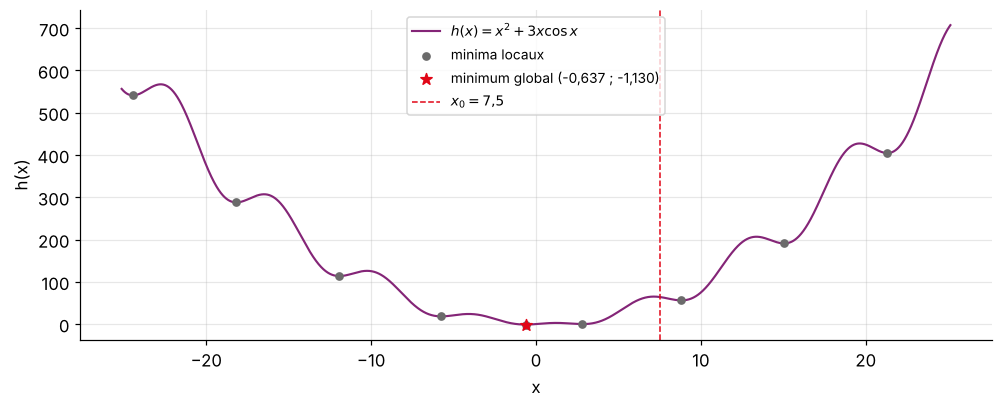

In [2]:
# Discrétisation de l'énoncé (y_n = -8π + 16π (n-1)/5000) et version qui atteint +8π
n = np.arange(1, 5001)
y_enonce = -8 * np.pi + 16 * np.pi * (n - 1) / 5000
y = np.linspace(a, b, 5000)            # = linspace Matlab : inclut les deux bornes
h_n = h_sujet3(y)
print(f"dernier point de l'énoncé : {y_enonce[-1]:.4f}  (8π = {8*np.pi:.4f})")

i = np.argmin(h_n)                      # min Matlab : [m, i] = min(h_n)
print(f"min sur la grille : h({y[i]:.4f}) = {h_n[i]:.4f}   max : {h_n.max():.1f}")

# Minima locaux exacts : zéros de h' encadrés par la grille, affinés par brentq
xm_grille, _ = minima_locaux(h_sujet3, a, b)
xm = np.array([brentq(dh_sujet3, x - 0.05, x + 0.05) for x in xm_grille])
hm = h_sujet3(xm)
X_GLOBAL = xm[np.argmin(hm)]
X_PIEGE = xm[np.argsort(hm)[1]]
X_LOCAL = brentq(dh_sujet3, 8.0, 9.5)   # minimum du bassin de x0 = 7,5
print(f"{len(xm)} minima locaux :")
for x, v in zip(xm, hm):
    print(f"   x = {x:8.4f}   h = {v:9.4f}" + ("   <- global" if x == X_GLOBAL else ""))

fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
ax.plot(y, h_n, color=VIOLET, lw=1.4, label=r"$h(x)=x^2+3x\cos x$")
ax.scatter(xm, hm, color=GRIS, s=22, zorder=3, label="minima locaux")
ax.scatter([X_GLOBAL], [hm.min()], color=ROUGE, s=60, marker="*", zorder=4,
           label=f"minimum global ({X_GLOBAL:.3f} ; {hm.min():.3f})".replace(".", ","))
ax.axvline(7.5, color=ROUGE, ls="--", lw=1, label=r"$x_0 = 7{,}5$")
ax.set_xlabel("x"); ax.set_ylabel("h(x)")
ax.legend(fontsize=9, loc="upper center")
sauver(fig, FIG / "s31_h.png"); plt.show()

resultats["q1"] = {"n_minima": int(len(xm)), "x_global": float(X_GLOBAL), "h_global": float(hm.min()),
                   "x_piege": float(X_PIEGE), "h_piege": float(h_sujet3(X_PIEGE)),
                   "x_local_x0": float(X_LOCAL), "h_local_x0": float(h_sujet3(X_LOCAL))}

**Lecture.** $h$ a **9 minima locaux** sur l'intervalle. Le minimum global est
$x^\star \approx -0{,}637$, $h(x^\star) \approx -1{,}130$ ; le `min` de la grille le retrouve à
$0{,}002$ près (pas de grille $16\pi/4999 \approx 0{,}01$). Le minimum local le plus proche en
valeur est $x \approx 2{,}805$ ($h \approx -0{,}075$) : c'est le piège du recuit (Q4).
$x_0 = 7{,}5$ est entre les maxima $7{,}14$ et $13{,}37$, dans le bassin du minimum local
$x \approx 8{,}814$ ($h \approx 56{,}0$).

La discrétisation de l'énoncé s'arrête à $25{,}1227$ au lieu de $8\pi \approx 25{,}1327$ :
il faut diviser par 4999 (c'est ce que fait `linspace`).

## Q2 · Gradient simple

$x_n = x_{n-1} - \alpha_n h'(x_{n-1})$ pour $n \ge 1$ (numérotation qui évite $\alpha_0 = 0{,}025/0$),
avec $\alpha_n = 0{,}025/n$ : $\sum \alpha_n = +\infty$ (série harmonique, on peut aller aussi loin
que nécessaire) et $\sum \alpha_n^2 < \infty$ (les pas s'éteignent). Par Taylor,
$h(x - \alpha_n h'(x)) \le h(x) - \alpha_n h'(x)^2 (1 - \alpha_n M/2)$ avec $M$ un majorant de $h''$ sur
le segment ; ici $M \approx 20{,}2$, $\alpha_n \le 0{,}025$ : $h$ diminue strictement à chaque pas.

On note $\bar x \approx 8{,}814$ le minimum local du bassin de $x_0$ et $e_n = x_n - \bar x$ l'erreur.
Près de $\bar x$, $e_{n+1} \approx (1 - c/n)\,e_n$ avec $c = 0{,}025\,h''(\bar x)$, d'où
$|e_n| \approx C n^{-c}$ (démonstration dans [demonstrations.md](demonstrations.md#q2)).

x_0 = 7.5, h'(x_0) = -5.065  ->  x_1 = 7.6266
x_N = 8.6606, h(x_N) = 56.2483   (minimum local visé : 8.8137, h = 56.0253)
h décroît à chaque pas : True
   |x_n - x*| pour n =    100 : 0.4086
   |x_n - x*| pour n =   1000 : 0.1531
   |x_n - x*| pour n =  10000 : 0.0509
   |x_n - x*| pour n = 100000 : 0.0162
pente log-log mesurée : -0.494   théorie -c = -0,025 h''(x*) = -0.505


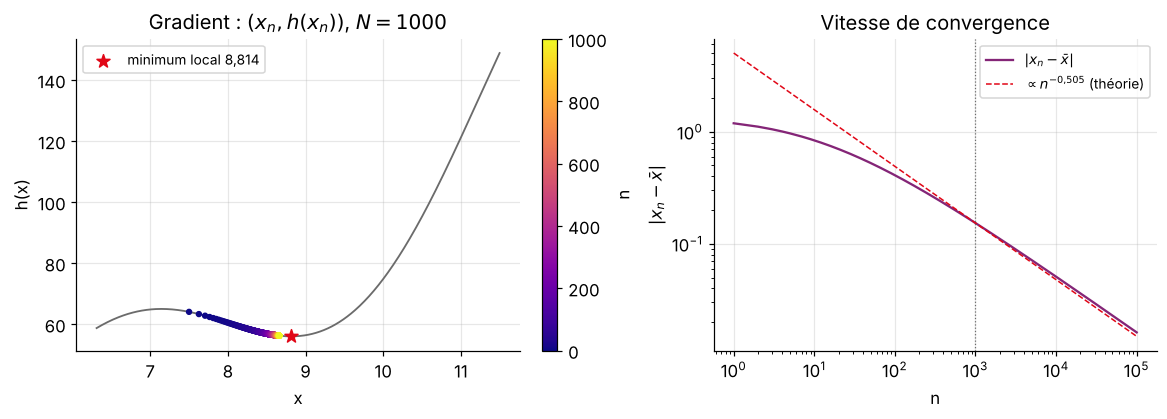

In [3]:
N = 1000
t0 = time.perf_counter()
xg = gradient_simple(dh_sujet3, 7.5, N)        # x_n = x_{n-1} - 0,025/n h'(x_{n-1})
duree_grad = time.perf_counter() - t0
print(f"x_0 = 7.5, h'(x_0) = {dh_sujet3(7.5):.3f}  ->  x_1 = {xg[1]:.4f}")
print(f"x_N = {xg[-1]:.4f}, h(x_N) = {h_sujet3(xg[-1]):.4f}   (minimum local visé : {X_LOCAL:.4f}, h = {h_sujet3(X_LOCAL):.4f})")
print("h décroît à chaque pas :", bool(np.all(np.diff(h_sujet3(xg)) <= 0)))

# Vitesse : on prolonge jusqu'à 10^5 itérations pour mesurer la pente de |x_n - x*|
xg_long = gradient_simple(dh_sujet3, 7.5, 100_000)
erreur = np.abs(xg_long - X_LOCAL)
for k in (100, 1000, 10_000, 100_000):
    print(f"   |x_n - x*| pour n = {k:>6} : {erreur[k]:.4f}")
c_theo = 0.025 * (2 - 6 * np.sin(X_LOCAL) - 3 * X_LOCAL * np.cos(X_LOCAL))
k = np.arange(1000, 100_001)
pente = np.polyfit(np.log(k), np.log(erreur[k]), 1)[0]
print(f"pente log-log mesurée : {pente:.3f}   théorie -c = -0,025 h''(x*) = {-c_theo:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.7), layout="constrained")
zoom = (y > 6.3) & (y < 11.5)
ax1.plot(y[zoom], h_n[zoom], color=GRIS, lw=1.2)
sc = ax1.scatter(xg, h_sujet3(xg), c=np.arange(N + 1), cmap="plasma", s=10, zorder=3)
ax1.scatter([X_LOCAL], [h_sujet3(X_LOCAL)], color=ROUGE, marker="*", s=80, zorder=4, label="minimum local 8,814")
ax1.set_xlabel("x"); ax1.set_ylabel("h(x)"); ax1.set_title(r"Gradient : $(x_n, h(x_n))$, $N = 1000$")
ax1.legend(fontsize=9); fig.colorbar(sc, ax=ax1, label="n")
nn = np.arange(1, 100_001)
ax2.loglog(nn, erreur[1:], color=VIOLET, lw=1.5, label=r"$|x_n - \bar x|$")
ax2.loglog(nn, erreur[1000] * (nn / 1000) ** (-c_theo), color=ROUGE, ls="--", lw=1,
           label=rf"$\propto n^{{-{c_theo:.3f}}}$ (théorie)".replace(".", "{,}"))
ax2.axvline(1000, color=GRIS, lw=0.8, ls=":")
ax2.set_xlabel("n"); ax2.set_ylabel(r"$|x_n - \bar x|$"); ax2.set_title("Vitesse de convergence"); ax2.legend(fontsize=9)
sauver(fig, FIG / "s32_gradient.png"); plt.show()

resultats["q2"] = {"N": N, "x_N": float(xg[-1]), "h_x_N": float(h_sujet3(xg[-1])),
                   "erreur_1000": float(erreur[1000]), "erreur_10000": float(erreur[10_000]),
                   "erreur_100000": float(erreur[100_000]), "pente_loglog": float(pente), "c_theorique": float(c_theo)}

**Lecture.** $h'(7{,}5) \approx -5{,}07 < 0$ : la suite part vers la droite et $h$ décroît à
chaque pas. Après $N = 1000$ itérations, $x_N \approx 8{,}661$ ($h \approx 56{,}25$) : on
**converge vers le minimum local** $8{,}814$ ($h \approx 56{,}03$), jamais vers le minimum global
($h \approx -1{,}13$). C'est attendu : partant de $x_0 = 7{,}5$, la descente ne peut pas
remonter le col en $7{,}14$.

La convergence est **lente** : il reste $0{,}153$ d'écart à $n = 1000$, puis $0{,}051$ et
$0{,}016$ à $n = 10^4$ et $10^5$ (facteur $\approx \sqrt{10}$ par décade). La pente mesurée en
log-log, $-0{,}494$, colle à la théorie $-c = -0{,}025\,h''(8{,}814) \approx -0{,}505$ :
l'erreur décroît en $1/\sqrt n$. Les « 1000 itérations » de l'énoncé suffisent pour **voir**
la convergence, pas pour l'atteindre à $10^{-3}$ près.

## Q3 · Recuit simulé

À chaque itération : $z \sim \mathcal U[x_n - \pi/2, x_n + \pi/2]$ ; on accepte $z$ avec
probabilité $\min(1, e^{-\Delta h_n/T_n})$, $\Delta h_n = h(z) - h(x_n)$, en pratique si
$U < e^{-\Delta h_n/T_n}$ avec $U \sim \mathcal U[0,1]$ (car $P(U < p) = p$). Températures
$T_n = 500 \times 0{,}99^n$. Choix d'implémentation : un $z$ hors de $[-8\pi, 8\pi]$ est refusé
(on minimise **sur l'intervalle**).

Pourquoi ça vise le global : à $T$ fixé, la chaîne a pour loi stationnaire
$\mu_T(x) \propto e^{-h(x)/T}$ (loi de Boltzmann ; équilibre détaillé, proposition symétrique), et
$\mu_T(x)/\mu_T(x^\star) = e^{-(h(x) - h(x^\star))/T} \to 0$ quand $T \to 0$ : la loi se
concentre sur les minima globaux.

x_N = -0.6503, h(x_N) = -1.1298   (minimum global : -0.6371, h = -1.1305)
meilleur point visité : -0.6334, h = -1.1304
T_n = 1 pour n = 618 ; T_N = 0.0216
taux d'acceptation par blocs de 100 itérations : [0.99 0.92 0.93 0.53 0.7  0.57 0.39 0.28 0.12 0.09]
dernière itération hors de ]x* - 0,5 ; x* + 0,5[ : n = 702


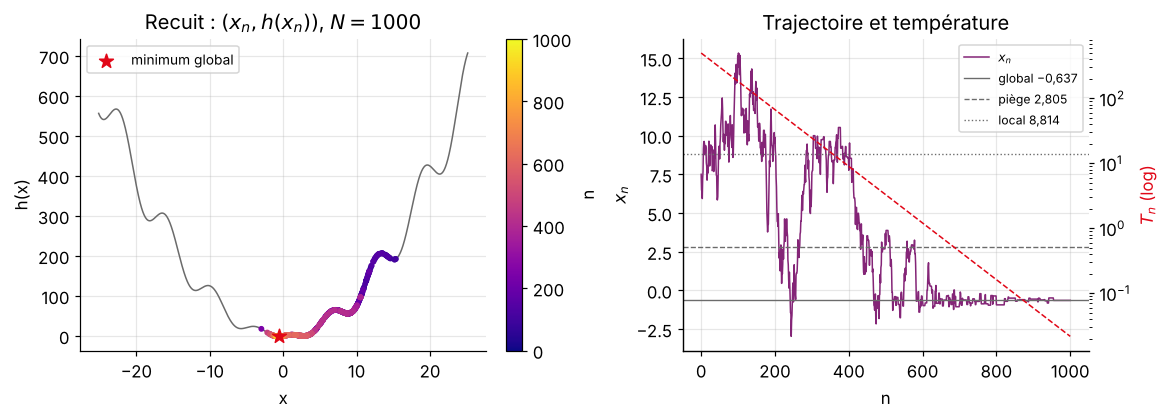

In [4]:
T0, ALPHA = 500.0, 0.99
t0 = time.perf_counter()
xr, acc = recuit_simule(h_sujet3, 7.5, N, rng, T0=T0, alpha=ALPHA, bornes=BORNES_SUJET3)
duree_recuit = time.perf_counter() - t0
Tn = T0 * ALPHA ** np.arange(N + 1)
meilleur = xr[np.argmin(h_sujet3(xr))]
print(f"x_N = {xr[-1]:.4f}, h(x_N) = {h_sujet3(xr[-1]):.4f}   (minimum global : {X_GLOBAL:.4f}, h = {hm.min():.4f})")
print(f"meilleur point visité : {meilleur:.4f}, h = {h_sujet3(meilleur):.4f}")
print(f"T_n = 1 pour n = {np.log(T0)/np.log(1/ALPHA):.0f} ; T_N = {Tn[-1]:.4f}")
print("taux d'acceptation par blocs de 100 itérations :", np.round(acc.reshape(10, 100).mean(axis=1), 2))
dernier_saut = np.max(np.nonzero(np.abs(xr - X_GLOBAL) > 0.5)[0]) if np.any(np.abs(xr - X_GLOBAL) > 0.5) else 0
print(f"dernière itération hors de ]x* - 0,5 ; x* + 0,5[ : n = {dernier_saut}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.7), layout="constrained")
ax1.plot(y, h_n, color=GRIS, lw=1.0)
sc = ax1.scatter(xr, h_sujet3(xr), c=np.arange(N + 1), cmap="plasma", s=8, zorder=3)
ax1.scatter([X_GLOBAL], [hm.min()], color=ROUGE, marker="*", s=90, zorder=4, label="minimum global")
ax1.set_xlabel("x"); ax1.set_ylabel("h(x)"); ax1.set_title(r"Recuit : $(x_n, h(x_n))$, $N = 1000$")
ax1.legend(fontsize=9); fig.colorbar(sc, ax=ax1, label="n")
ax2.plot(xr, color=VIOLET, lw=1.0, label=r"$x_n$")
for xx, lab, st in ((X_GLOBAL, "global −0,637", "-"), (X_PIEGE, "piège 2,805", "--"), (X_LOCAL, "local 8,814", ":")):
    ax2.axhline(xx, color=GRIS, ls=st, lw=0.9, label=lab)
ax2.legend(fontsize=8, loc="upper right")
ax2.set_xlabel("n"); ax2.set_ylabel(r"$x_n$")
ax3 = ax2.twinx(); ax3.semilogy(Tn, color=ROUGE, lw=1, ls="--"); ax3.set_ylabel(r"$T_n$ (log)", color=ROUGE)
ax3.grid(False); ax2.set_title("Trajectoire et température")
sauver(fig, FIG / "s33_recuit.png"); plt.show()

resultats["q3"] = {"T0": T0, "alpha": ALPHA, "N": N, "x_N": float(xr[-1]), "h_x_N": float(h_sujet3(xr[-1])),
                   "meilleur": float(meilleur), "T_N": float(Tn[-1]),
                   "taux_acceptation_blocs": [float(v) for v in acc.reshape(10, 100).mean(axis=1)]}

**Lecture.** Partie du même $x_0 = 7{,}5$, la trajectoire **sort du bassin** du minimum local :
tant que $T_n$ est grand, les montées sont acceptées (taux $0{,}99$ sur les 100 premières
itérations) et la suite explore environ $[-3 ; 15{,}3]$. Quand $T_n$ passe sous 1 (vers $n = 618$), elle se
fixe : dernière sortie de $]x^\star - 0{,}5, x^\star + 0{,}5[$ à $n = 702$, puis le taux
d'acceptation tombe à $0{,}09$. Au final $x_N \approx -0{,}650$, $h(x_N) \approx -1{,}1298$,
contre $h(x^\star) \approx -1{,}1305$ : le recuit a trouvé le **minimum global** (meilleur point
visité : $-0{,}633$). La précision finale est limitée car les propositions restent larges
($\pm\pi/2$) même à basse température.

## Q4 · Comparaison

Un seul lancer du recuit ne prouve rien : c'est un algorithme **aléatoire**. On le relance
$R = 1000$ fois (tirages indépendants) et on estime la proportion de succès
$\hat p$, avec son erreur-type $\sqrt{\hat p(1 - \hat p)/R}$.

1000 lancers du recuit (N = 1000) :
   minimum global  : 0.738 ± 0.027 (IC 95 %)
   piège x = 2,805 : 0.259 ± 0.027
   ailleurs        : 0.003
gradient : 0 succès (déterministe : toujours 8.661)


variante alpha = 0,995, N = 2000 (400 lancers) : succès 0.770 ± 0.041
écart en erreurs-types : 1.27
temps : gradient 1.3 ms ; un recuit 3.0 ms ; 1000 recuits 3.5 s


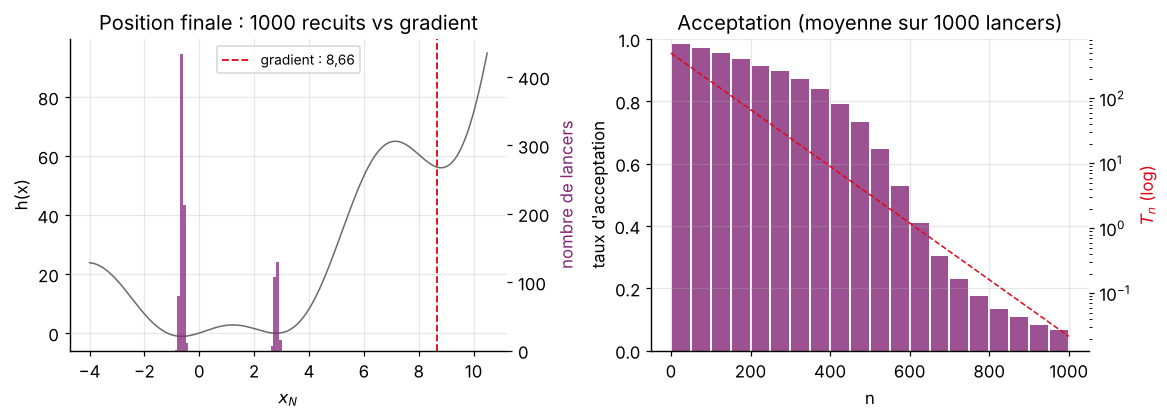

1420

In [5]:
R = 1000   # lancers indépendants (le générateur continue : chaque lancer a ses propres tirages)
t0 = time.perf_counter()
lancers = [recuit_simule(h_sujet3, 7.5, N, rng, T0=T0, alpha=ALPHA, bornes=BORNES_SUJET3) for _ in range(R)]
duree_R = time.perf_counter() - t0
fins = np.array([x[-1] for x, _ in lancers])
taux_acc = np.mean([acc_ for _, acc_ in lancers], axis=0)

def proportion(masque):
    p = masque.mean(); et = np.sqrt(p * (1 - p) / len(masque))
    return p, et

p_glob, et_glob = proportion(np.abs(fins - X_GLOBAL) < 0.5)
p_piege, et_piege = proportion(np.abs(fins - X_PIEGE) < 0.5)
p_autre = 1 - p_glob - p_piege
print(f"{R} lancers du recuit (N = {N}) :")
print(f"   minimum global  : {p_glob:.3f} ± {1.96*et_glob:.3f} (IC 95 %)")
print(f"   piège x = 2,805 : {p_piege:.3f} ± {1.96*et_piege:.3f}")
print(f"   ailleurs        : {p_autre:.3f}")
print(f"gradient : 0 succès (déterministe : toujours {xg[-1]:.3f})")

# Variante : refroidir deux fois plus lentement (alpha = 0,995, N = 2000)
R2 = 400
fins_lent = np.array([recuit_simule(h_sujet3, 7.5, 2000, rng, T0=T0, alpha=0.995, bornes=BORNES_SUJET3)[0][-1]
                      for _ in range(R2)])
p_lent, et_lent = proportion(np.abs(fins_lent - X_GLOBAL) < 0.5)
print(f"variante alpha = 0,995, N = 2000 ({R2} lancers) : succès {p_lent:.3f} ± {1.96*et_lent:.3f}")
print(f"écart en erreurs-types : {(p_lent - p_glob)/np.hypot(et_lent, et_glob):.2f}")

print(f"temps : gradient {duree_grad*1e3:.1f} ms ; un recuit {duree_recuit*1e3:.1f} ms ; {R} recuits {duree_R:.1f} s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.7), layout="constrained")
zoom = (y > -4) & (y < 10.5)
ax1.plot(y[zoom], h_n[zoom], color=GRIS, lw=1.0)
ax1b = ax1.twinx()
ax1b.hist(fins, bins=np.linspace(-4, 10.5, 146), color=VIOLET, alpha=0.75)
ax1b.set_ylabel("nombre de lancers", color=VIOLET); ax1b.grid(False)
ax1.axvline(xg[-1], color=ROUGE, ls="--", lw=1.2, label=f"gradient : {xg[-1]:.2f}".replace(".", ","))
ax1.set_xlabel(r"$x_N$"); ax1.set_ylabel("h(x)")
ax1.set_title(f"Position finale : {R} recuits vs gradient"); ax1.legend(fontsize=9, loc="upper center")
blocs = taux_acc.reshape(20, 50).mean(axis=1)
ax2.bar(np.arange(20) * 50 + 25, blocs, width=45, color=VIOLET, alpha=0.8, label="taux d'acceptation moyen")
ax2.set_xlabel("n"); ax2.set_ylabel("taux d'acceptation"); ax2.set_ylim(0, 1)
ax3 = ax2.twinx(); ax3.semilogy(Tn, color=ROUGE, ls="--", lw=1); ax3.set_ylabel(r"$T_n$ (log)", color=ROUGE); ax3.grid(False)
ax2.set_title(f"Acceptation (moyenne sur {R} lancers)")
sauver(fig, FIG / "s34_comparaison.png"); plt.show()

resultats["q4"] = {"R": R, "succes_global": float(p_glob), "ic95_global": float(1.96 * et_glob),
                   "piege": float(p_piege), "ic95_piege": float(1.96 * et_piege), "ailleurs": float(p_autre),
                   "variante_alpha": 0.995, "variante_N": 2000, "variante_R": R2,
                   "variante_succes": float(p_lent), "variante_ic95": float(1.96 * et_lent),
                   "acceptation_debut": float(taux_acc[:100].mean()), "acceptation_fin": float(taux_acc[-100:].mean()),
                   "duree_gradient_ms": duree_grad * 1e3, "duree_recuit_ms": duree_recuit * 1e3}
(FIG / "resultats.json").write_text(json.dumps(resultats, indent=2, ensure_ascii=False))

**Lecture.**

- **Garantie.** Le gradient finit **toujours** en $8{,}66$, dans le minimum local : 0 succès, par
  construction. Le recuit atteint le minimum global dans **73,8 % ± 2,7 %** des lancers (IC à
  95 %), et reste piégé en $2{,}805$ dans **25,9 %** des cas (3 lancers sur 1000 ailleurs). L'affirmation
  de l'énoncé (« ce choix garantit la convergence presque sûre ») est **fausse** : avec
  $T_n = T_0\alpha^n$, $\sum_n e^{-d/T_n} < \infty$ pour toute hauteur de col $d > 0$, donc la chaîne
  ne franchit presque sûrement plus qu'un nombre fini de cols (Borel-Cantelli) ; elle **gèle**,
  et ces 25,9 % sont la proportion limite. La garantie théorique (Hajek, 1988, espace fini) est
  une convergence **en probabilité**, avec $T_n = c/\ln n$ et $c$ au moins égal à la profondeur du
  minimum local non global le plus profond ($\approx 26$ pour de petits pas, $\approx 12$ avec des
  sauts de $\pm\pi/2$) : beaucoup trop lent en pratique. Intuition : les deux minima les plus bas ne diffèrent
  que de $1{,}06$ ; la chaîne gèle vers $T \approx 1$, où la loi de Boltzmann met environ 25 %
  de sa masse dans le bassin de $2{,}805$.
- **Refroidir plus lentement** ($\alpha = 0{,}995$, $N = 2000$) donne 77,0 % ± 4,1 % : l'écart
  avec 73,8 % ne vaut que 1,27 erreur-type, **non significatif**. Ralentir un refroidissement
  géométrique ne suffit pas à lever ce piège.
- **Vitesse.** Le gradient converge (vers le local) en $n^{-1/2}$ ; le recuit n'atteint le
  bon bassin qu'après $\approx 700$ itérations et sa précision finale est grossière. Coûts
  mesurés (ordre de grandeur, variable d'une machine à l'autre) : $\approx 1$ ms pour le
  gradient, quelques ms par recuit, quelques secondes pour les 1000 recuits nécessaires à
  l'évaluer.
- **Compréhension et mise en œuvre.** Gradient : une ligne, un paramètre (le pas), mais il faut
  $h'$. Recuit : seulement des évaluations de $h$ (pas de dérivée), mais trois réglages
  ($T_0$, $\alpha$, largeur de $g_n$), une analyse par chaînes de Markov, et un résultat à juger
  **statistiquement** sur plusieurs lancers.

En pratique on combine : recuit pour explorer, puis gradient depuis le meilleur point visité pour
affiner, ou plusieurs recuits en gardant le meilleur. Avec 2 lancers indépendants, la probabilité
d'échec tombe à $0{,}262^2 \approx 7\,\%$.